# Investigate alleles that increased abundance

Almost all variants with abundance changes that surpass assay variability are decreases in abundance. For the very few cases that increased abundance, we want to see if there is anything biologically interesting going on here.

In [1]:
import polars as pl
import sys
import seaborn as sns
from matplotlib import pyplot as plt
import pandas as pd
import sys

sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

In [5]:
outputs_dir = "../3_outputs"
scores = pl.read_csv(f"{outputs_dir}/annotated_perturbation_scores.csv", infer_schema_length=1000000)
scores

symbol,node_type,nt_change,aa_change,pla,well,coordinates,n_cells,orf_id,mut_id,valid_well,avg_gfp,avg_mcherry,avg_GFP_mCherry_ratio,wt_GFP_mCherry_ratio,allele_wt_ratio,zscore,zcat,allele_wt_log2fc,zscore_log2fc_mean_norm_by_all_wt_mean,allele_wt_log2fc_pvalue,zscore_log2fc_mean_norm_by_each_wt,symbol_right,ensembl_gene_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change_right,aa_change_right,collection,entry_plate_orig,entry_well_orig,entry_plate_conso,entry_well_conso,entry_seq_pool,db_plate,db_well,…,SomaticClinicalImpact_dbnsfp,SomaticClinicalImpactLastEvaluated_dbnsfp,ReviewStatusClinicalImpact_dbnsfp,Oncogenicity_dbnsfp,OncogenicityLastEvaluated_dbnsfp,ReviewStatusOncogenicity_dbnsfp,SCVsForAggregateGermlineClassification_dbnsfp,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,plddt,rsa,OMIM_IDs,inheritance_pattern,disease_modules,disease_module_count,OMIM_disease_names,gene_allele,median_gfp,median_mcherry,median_GFP_mCherry_ratio,wt_GFP_mCherry_ratio_median,allele_wt_ratio_median,zscore_median,zcat_median,zscore_log2fc_median_norm_by_each_wt,dualipa_abun_score,dualipa_abun_change,dualipa_abun_chg_dir,plddt_f32,rsa_f32,RSA_Category,pLDDT_Category
str,str,str,str,i64,str,str,i64,i64,i64,bool,f64,f64,f64,f64,f64,f64,i64,f64,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,…,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,f64,f64,str,str,str,i64,str,str,f64,f64,f64,f64,f64,f64,i64,f64,f64,str,str,f64,f64,str,str
"""KCNJ2""","""allele""","""821A>T""","""Asp274Val""",11,"""H06""","""11_H06""",4976,100016069,2638,true,1736.815259,5002.388278,0.851111,1.862762,0.456908,-1.775144,-1,-1.130024,-4.834053,0.000001,-3.08904,"""KCNJ2""","""ENSG00000123700""","""CCSBVarC008340""","""ALE00008326""","""NC_000017.11:70175860:A:T""","""821A>T""","""Asp274Val""","""Edgotyping3""","""VUSMutGDEh010""","""D06""","""GDEhDisVCh_40005""","""C10""",1.0,"""VUSMutGDDh010""","""D06""",…,"""-""","""-""","""-""","""-""","""-""","""-""","""SCV000223548""","""-""","""-""","""821A>T ""","""Asp274Val""","""NM_000891.3""",1.0,"""4_VUS""",93.79,0.306748,null,null,"""Rare genetic cardiac disease; …",2,null,"""KCNJ2_Asp274Val""",897.920013,2918.650024,0.253414,0.841771,0.301048,-2.53293,-2,-3.99069,-3.08904,"""Uncertain""","""Increase""",93.79,0.306748,"""10-90""",""">90"""
"""PKP2""","""allele""","""1415A>G""","""Lys472Arg""",19,"""F05""","""19_F05""",2900,54308,3072,true,960.198308,1368.839077,0.887373,0.924631,0.959706,-0.247815,0,-0.059336,-0.181273,0.856153,-0.18025,"""PKP2""","""ENSG00000057294""","""CCSBVarC008023""","""ALE00008009""","""NC_000012.12:32841169:T:C""","""1415A>G""","""Lys472Arg""","""Edgotyping3""","""VUSMutGDEh015""","""H02""","""GDEhDisVCh_40015""","""E08""",1.0,"""VUSMutGDDh015""","""H02""",…,"""-""","""-""","""-""","""-""","""-""","""-""","""SCV000236225|SCV000761608|SCV0…","""-""","""-""","""1415A>G ""","""Lys472Arg""","""NM_001005242.3""",2.0,"""4_VUS""",96.38,0.014634,"""['609040']""","""autosomal dominant""","""Rare genetic cardiac disease; …",2,"""ARRHYTHMOGENIC RIGHT VENTRICUL…","""PKP2_Lys472Arg""",718.52002,912.559998,0.674567,0.629182,1.072134,0.115417,0,0.244007,-0.18025,"""N""","""Increase""",96.38,0.014634,"""<10""",""">90"""
"""KCNJ2""","""allele""","""899G>A""","""Gly300Asp""",11,"""D07""","""11_D07""",8822,100016069,2641,true,1801.536166,6450.702463,0.526546,1.862762,0.282669,-2.304423,-2,-1.822812,-7.844631,4.3423e-15,-4.97117,"""KCNJ2""","""ENSG00000123700""","""CCSBVarC008343""","""ALE00008329""","""NC_000017.11:70175938:G:A""","""899G>A""","""Gly300Asp""","""Edgotyping3""","""VUSMutGDEh010""","""G06""","""GDEhDisVCh_40005""","""F10""",1.0,"""VUSMutGDDh010""","""G06""",…,"""-""","""-""","""-""","""-""","""-""","""-""","""SCV001446813|SCV004571381""","""-""","""-""","""899G>A ""","""Gly300Asp""","""NM_000891.3""",2.0,"""1_Pathog

## 1. Variants with increased abundance

In [7]:
incr_abun = scores.filter((pl.col("dualipa_abun_change")=="Y")&(pl.col("dualipa_abun_chg_dir")=="Increase"))
print(incr_abun.select(['symbol', 'aa_change', 'dualipa_abun_score', 'clinvar_clnsig_clean', 'StarStatus']))

shape: (20, 5)
┌────────┬───────────┬────────────────────┬──────────────────────┬────────────┐
│ symbol ┆ aa_change ┆ dualipa_abun_score ┆ clinvar_clnsig_clean ┆ StarStatus │
│ ---    ┆ ---       ┆ ---                ┆ ---                  ┆ ---        │
│ str    ┆ str       ┆ f64                ┆ str                  ┆ f64        │
╞════════╪═══════════╪════════════════════╪══════════════════════╪════════════╡
│ SH3BP2 ┆ Gly420Arg ┆ 2.335735           ┆ 1_Pathogenic         ┆ null       │
│ NAA10  ┆ Arg116Trp ┆ 2.654036           ┆ 1_Pathogenic         ┆ 2.0        │
│ MID1   ┆ Pro151Leu ┆ 3.449523           ┆ 4_VUS                ┆ 1.0        │
│ PKP2   ┆ Pro156Ala ┆ 2.210308           ┆ 4_VUS                ┆ 2.0        │
│ KLHL3  ┆ Glu85Ala  ┆ 3.952288           ┆ 1_Pathogenic         ┆ null       │
│ …      ┆ …         ┆ …                  ┆ …                    ┆ …          │
│ PKP2   ┆ Thr263Met ┆ 2.55075            ┆ 4_VUS                ┆ 2.0        │
│ KLHL3  ┆ Met78Val  ┆ 2.

## 2. Group the variants by gene

<Figure size 640x480 with 0 Axes>

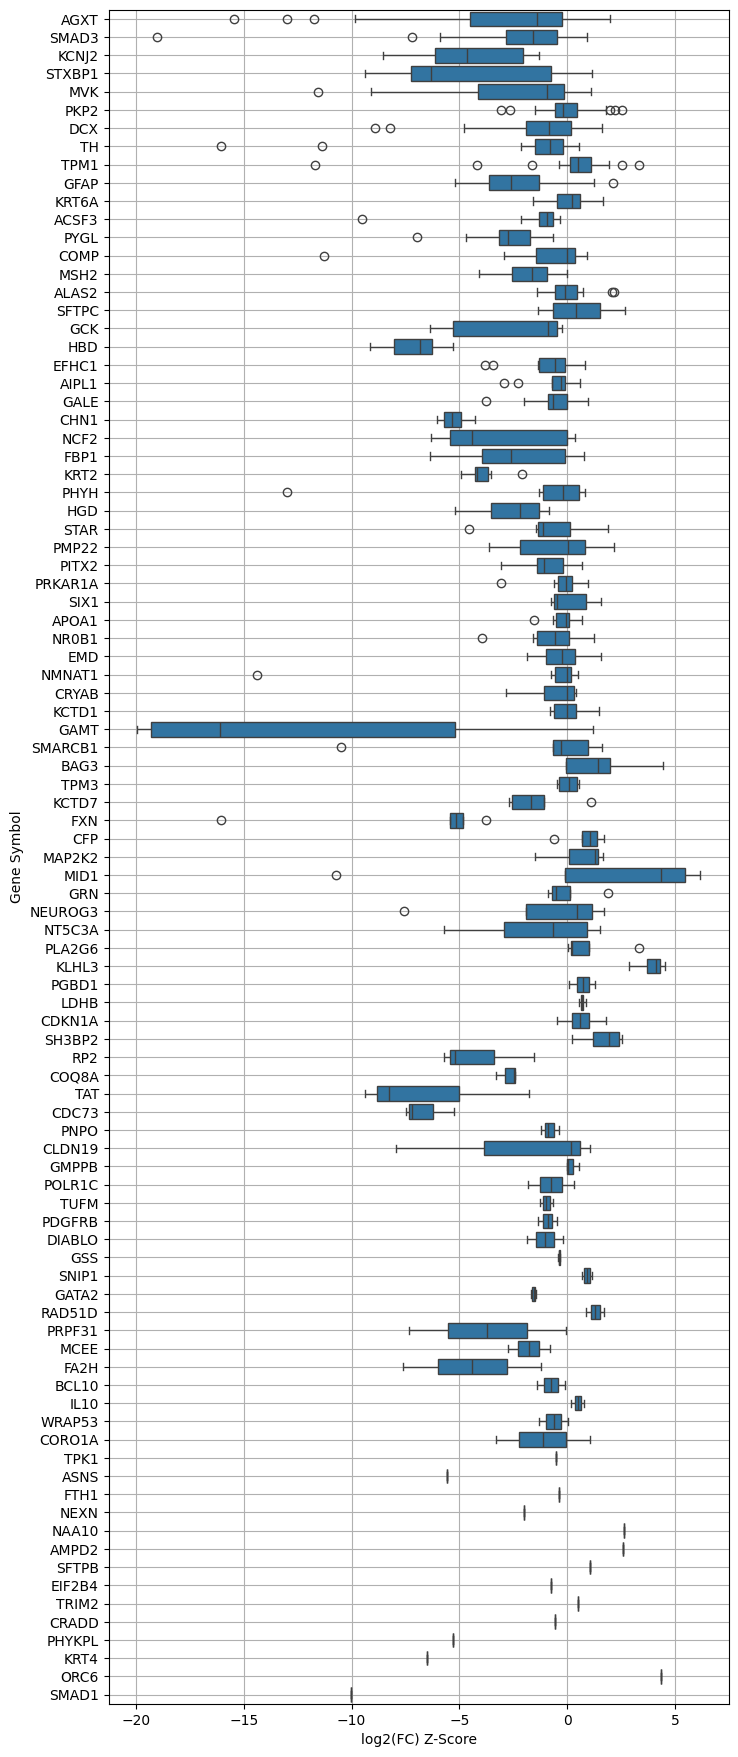

In [10]:
symbol_medians = scores.filter(~pl.col("dualipa_abun_score").is_null()).group_by("symbol").agg(
    pl.col("dualipa_abun_score").mean().alias("gene_mean")
).sort("gene_mean")

symbol_order = symbol_medians.select('symbol').to_series().to_list()
scores_plot = scores.join(symbol_medians, on="symbol").to_pandas()
scores_plot['symbol'] = pd.Categorical(scores_plot['symbol'], categories=symbol_order, ordered=True)

dual_ipa_df = pl.DataFrame(scores_plot)
dual_gene = dual_ipa_df.group_by(
    ["symbol"]
).len().rename(
    {"len": "total_counts_all"}
).sort("total_counts_all", descending=True)

plt.clf()
fig, ax = plt.subplots(1,1,figsize=(8, 22))
sns.boxplot(data=scores_plot, x="dualipa_abun_score", y="symbol", ax=ax, order=dual_gene["symbol"])
ax.set_xlabel("log2(FC) Z-Score")
ax.set_ylabel("Gene Symbol")
ax.grid()
plt.show()

<Figure size 640x480 with 0 Axes>

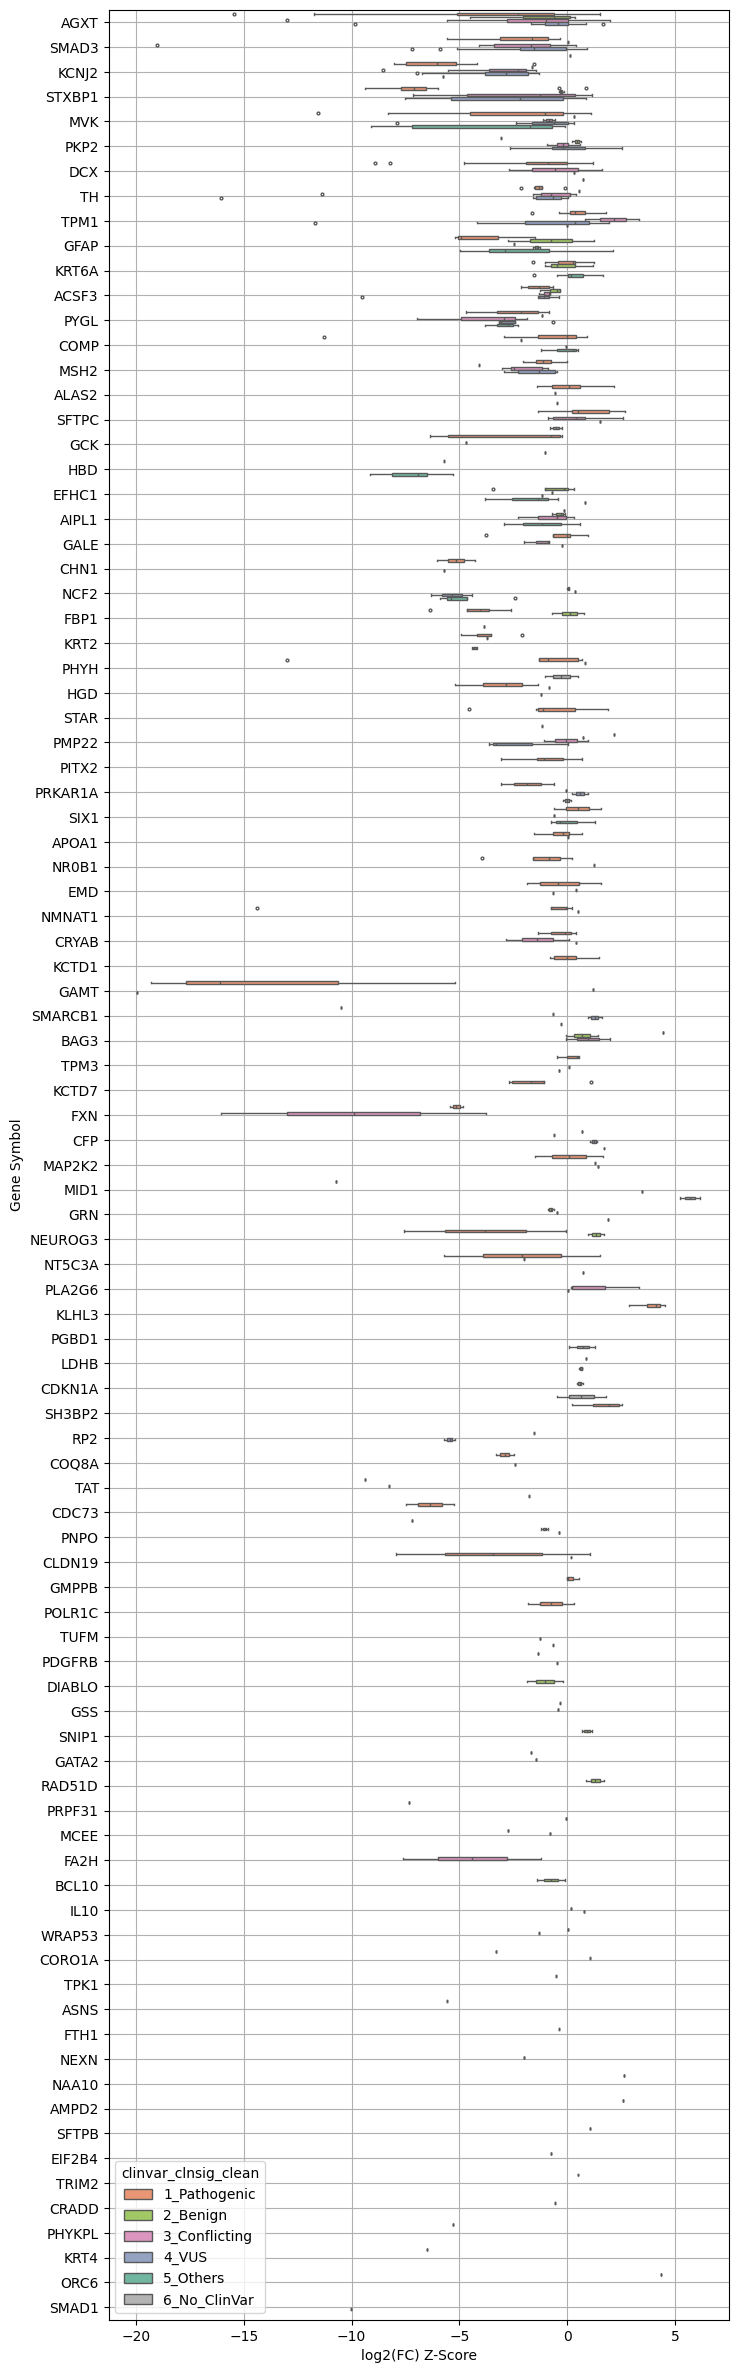

In [11]:
plt.clf()
fig, ax = plt.subplots(1,1,figsize=(8, 30))
sns.boxplot(data=scores_plot, x="dualipa_abun_score", y="symbol", 
            palette=palette_dict["clinvar_clnsig_clean"], ax=ax, 
            hue="clinvar_clnsig_clean", 
            hue_order=sorted(scores_plot.dropna(subset="clinvar_clnsig_clean")["clinvar_clnsig_clean"].unique()),
            gap=.2,
            fliersize=2,
            order=dual_gene["symbol"]
           )

ax.set_xlabel("log2(FC) Z-Score")
ax.set_ylabel("Gene Symbol")
ax.grid()
plt.show()

<Figure size 640x480 with 0 Axes>

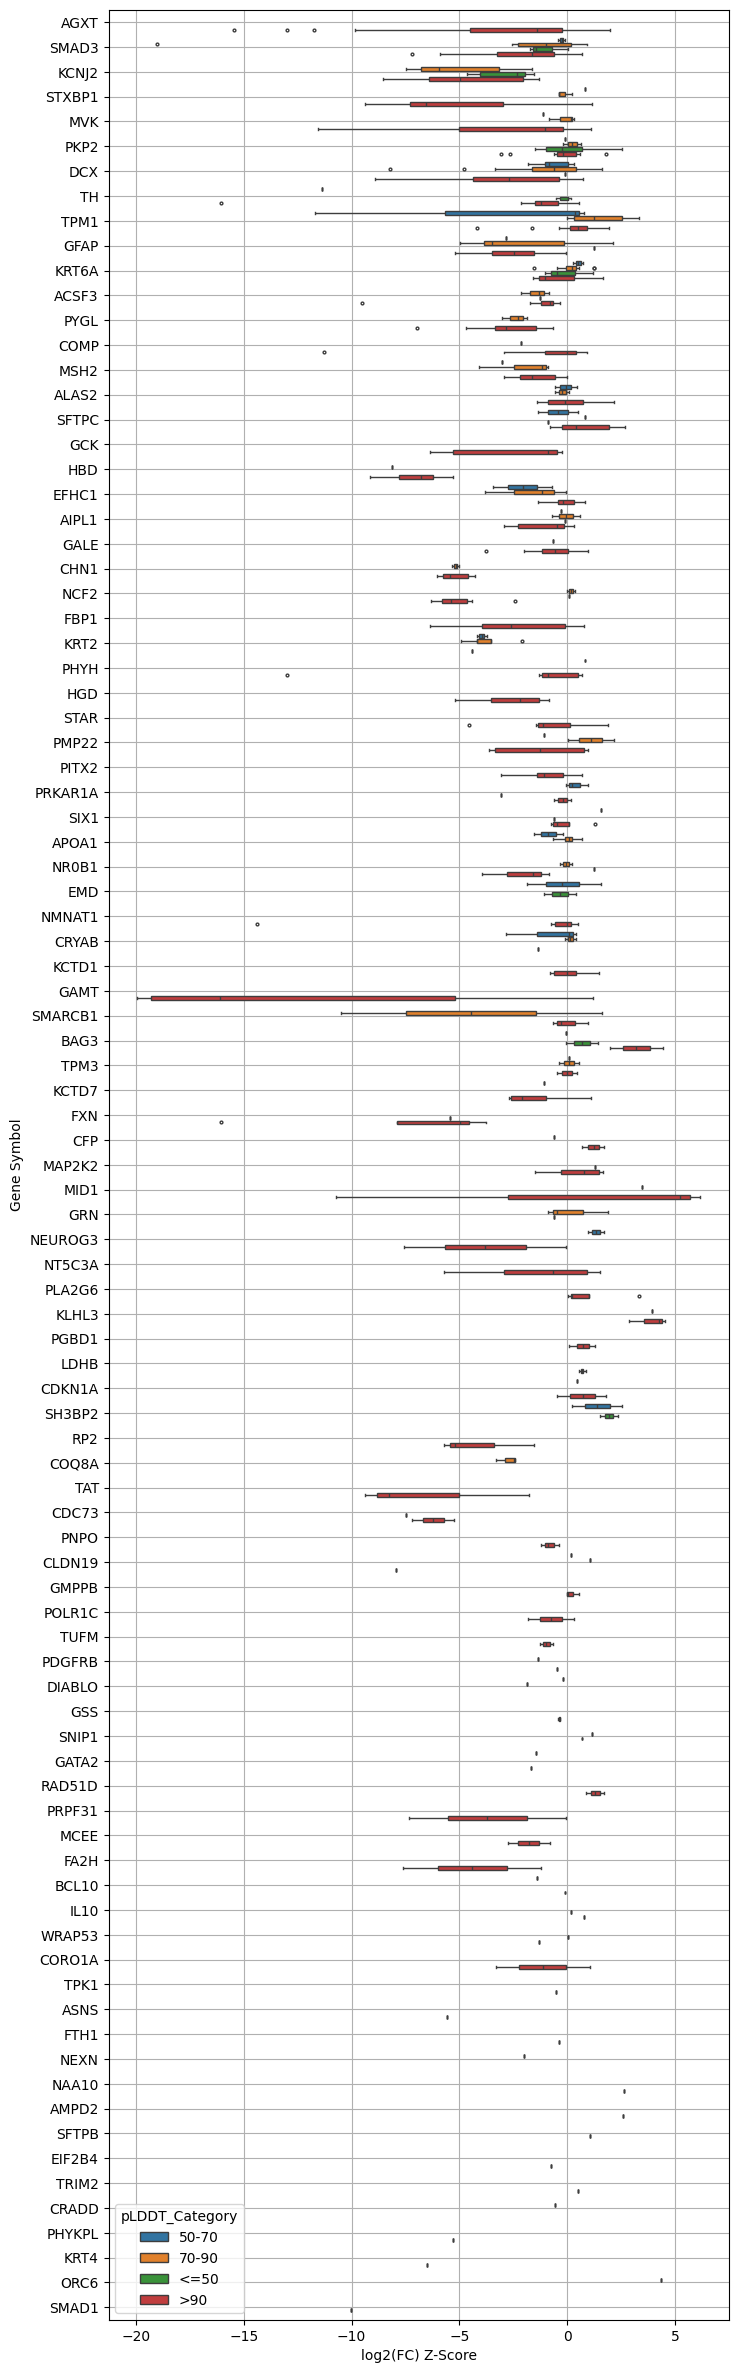

In [12]:
plt.clf()
fig, ax = plt.subplots(1,1,figsize=(8, 30))
sns.boxplot(data=scores_plot, x="dualipa_abun_score", y="symbol", 
            ax=ax, 
            hue="pLDDT_Category", 
            hue_order=sorted(scores_plot.dropna(subset="pLDDT_Category")["pLDDT_Category"].unique()),
            gap=.2,
            fliersize=2,
            order=dual_gene["symbol"]
           )

ax.set_xlabel("log2(FC) Z-Score")
ax.set_ylabel("Gene Symbol")
ax.grid()
plt.show()

<Figure size 640x480 with 0 Axes>

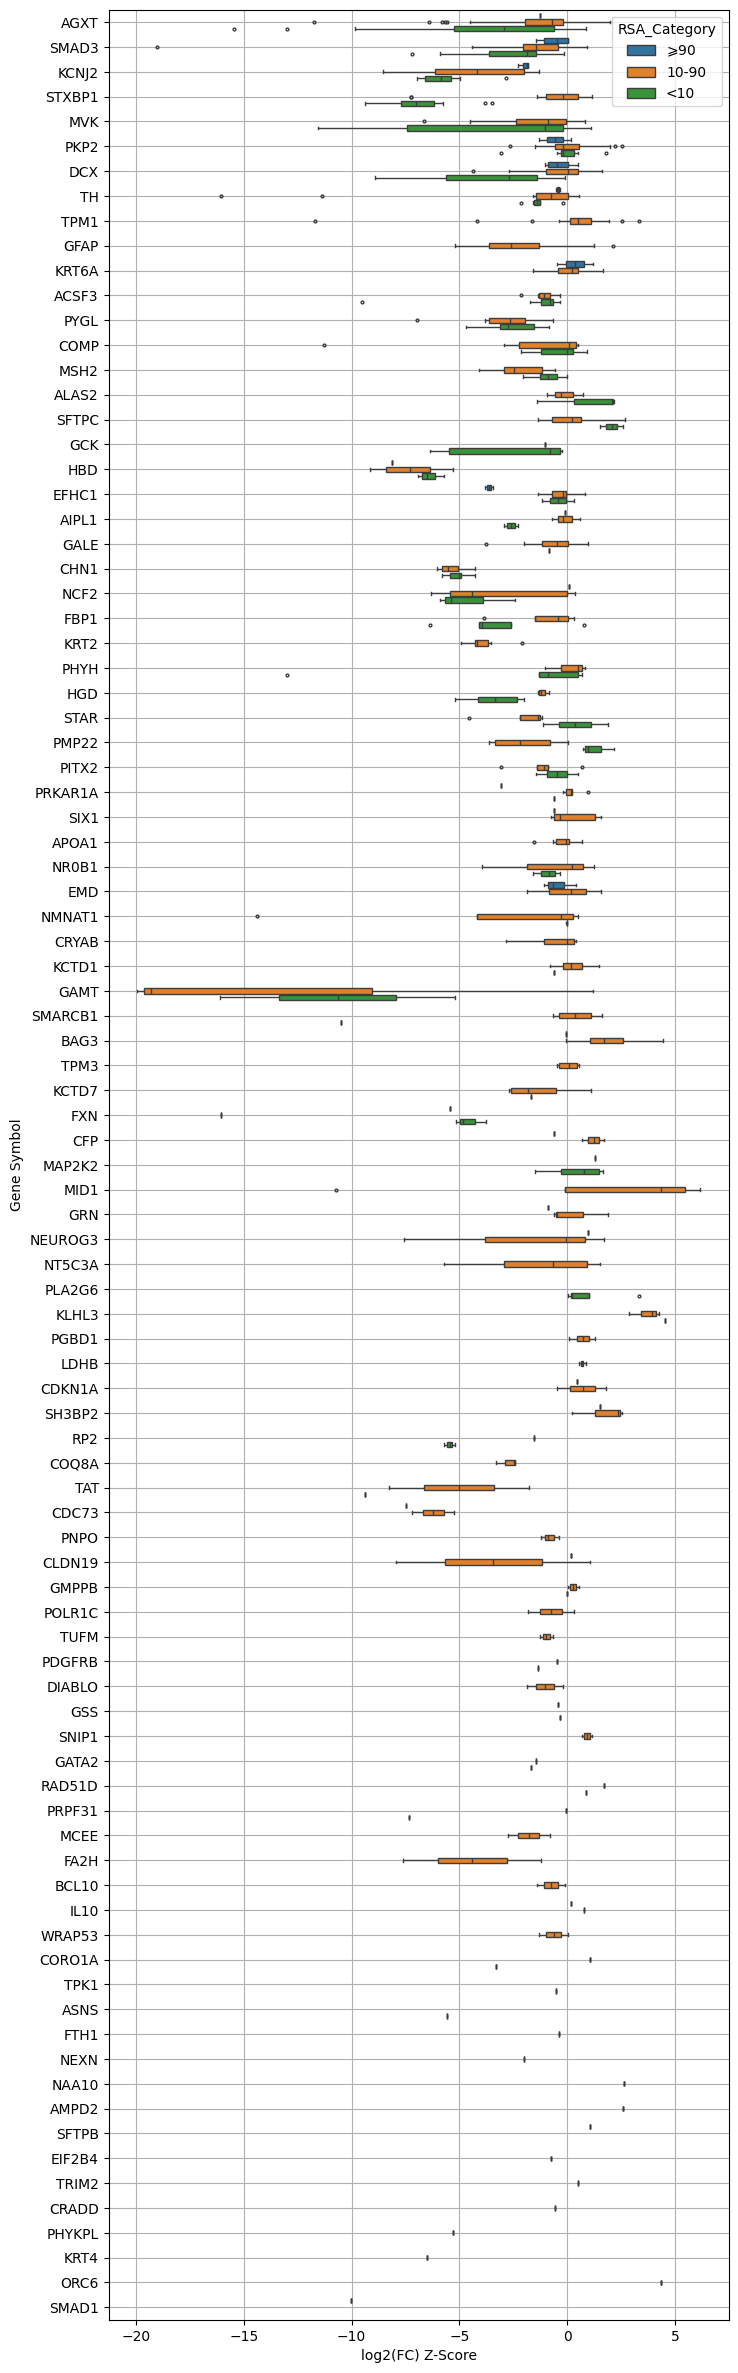

In [13]:
plt.clf()
fig, ax = plt.subplots(1,1,figsize=(8, 30))
sns.boxplot(data=scores_plot, x="dualipa_abun_score", y="symbol", 
            ax=ax, 
            hue="RSA_Category", 
            hue_order=sorted(scores_plot.dropna(subset="RSA_Category")["RSA_Category"].unique()),
            gap=.2,
            fliersize=2,
            order=dual_gene["symbol"]
           )

ax.set_xlabel("log2(FC) Z-Score")
ax.set_ylabel("Gene Symbol")
ax.grid()
plt.show()

## 3. Plot hits

In [23]:
dual_ipa_df_clean_hit = dual_ipa_df.with_columns(
    pl.when(pl.col("dualipa_abun_change")=="Y")
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("dualipa_hit")
)

### 3.1 Plot hits by ClinVar

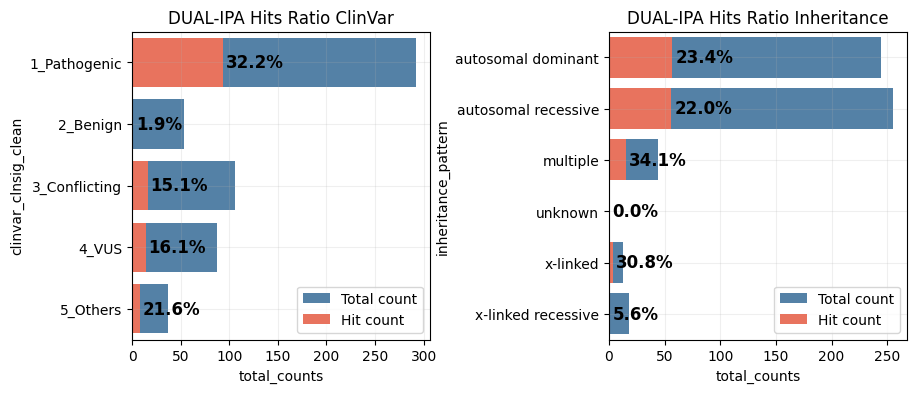

In [32]:
dual_ipa_df_metric = dual_ipa_df_clean_hit.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS","5_Others","6_No_ClinVar"]) #pl.col("Gene")!="BRCA1" #
).drop_nulls("inheritance_pattern")

fig, axes = plt.subplots(1,2,figsize=(10,4))
plot_assay_hit_by_category(dual_ipa_df_metric, "dualipa_hit", "clinvar_clnsig_clean", f"DUAL-IPA Hits Ratio ClinVar", ax=axes[0])
plot_assay_hit_by_category(dual_ipa_df_metric, "dualipa_hit", "inheritance_pattern", f"DUAL-IPA Hits Ratio Inheritance", ax=axes[1])
plt.subplots_adjust(wspace=.6)
plt.show()

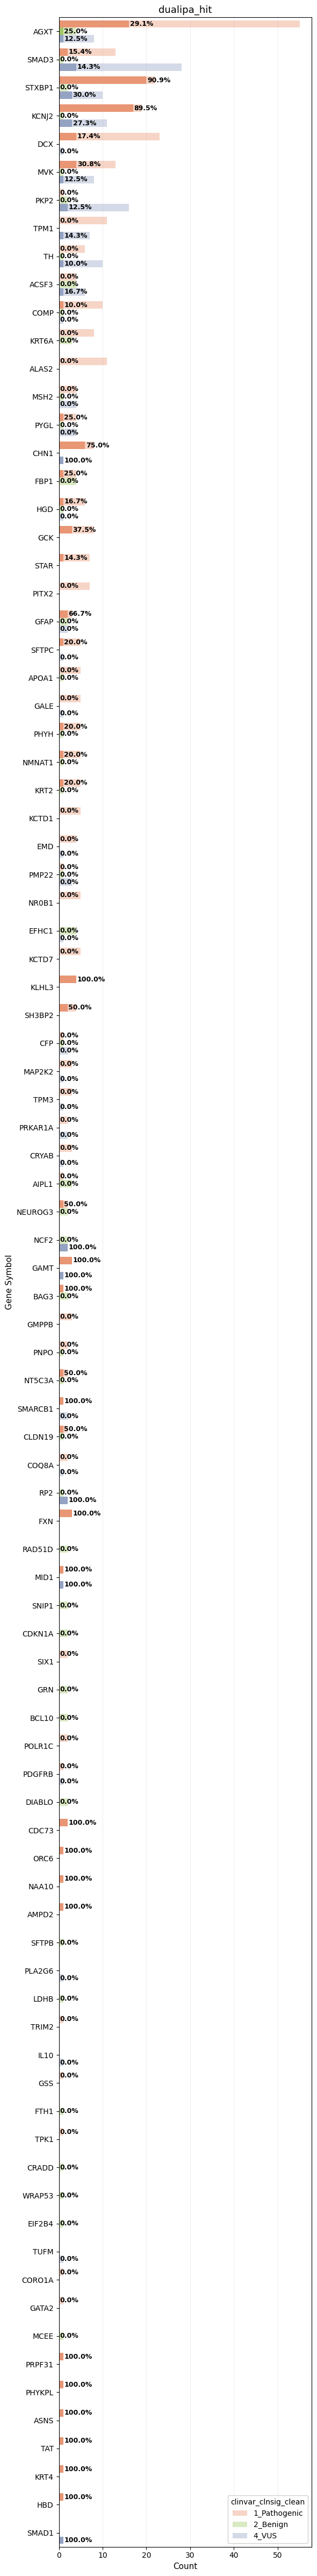

,symbol,clinvar_clnsig_clean,total_counts,hit_counts,hit_perc,total_counts_all
0,AGXT,1_Pathogenic,55,16,29.090909,67
1,AGXT,2_Benign,4,1,25.000000,67
2,AGXT,4_VUS,8,1,12.500000,67
3,SMAD3,1_Pathogenic,13,2,15.384615,42
4,SMAD3,2_Benign,1,0,0.000000,42
...,...,...,...,...,...,...
145,ASNS,1_Pathogenic,1,1,100.000000,1
146,TAT,1_Pathogenic,1,1,100.000000,1
147,KRT4,1_Pathogenic,1,1,100.000000,1
148,HBD,1_Pathogenic,1,1,100.000000,1


In [33]:
plot_gene_level_summary(
    assay_df=dual_ipa_df_clean_hit.filter(
        pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","4_VUS"])
    ),
    assay="dualipa_hit",
    palette=palette_dict["clinvar_clnsig_clean"]
)

### 3.2 Plot hits by structural info

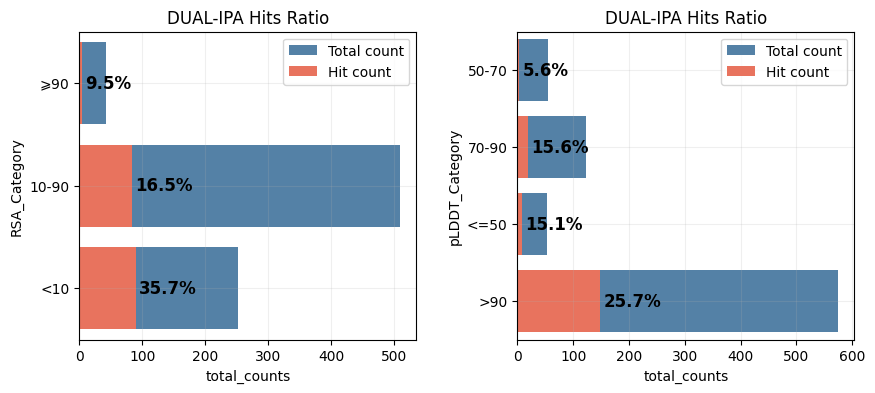

In [34]:
fig, axes = plt.subplots(1,2,figsize=(10,4))
plot_assay_hit_by_category(dual_ipa_df_clean_hit, "dualipa_hit", "RSA_Category", f"DUAL-IPA Hits Ratio", ax=axes[0])
plot_assay_hit_by_category(dual_ipa_df_clean_hit, "dualipa_hit", "pLDDT_Category", f"DUAL-IPA Hits Ratio", ax=axes[1])
plt.subplots_adjust(wspace=.3)
plt.show()

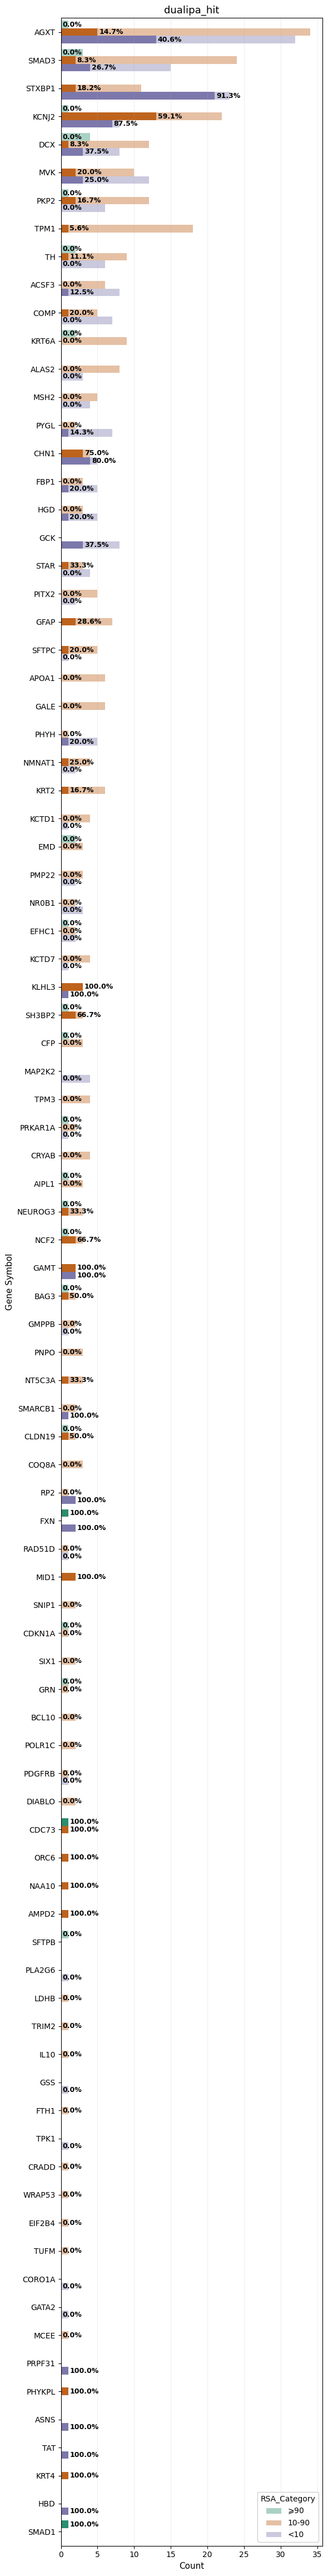

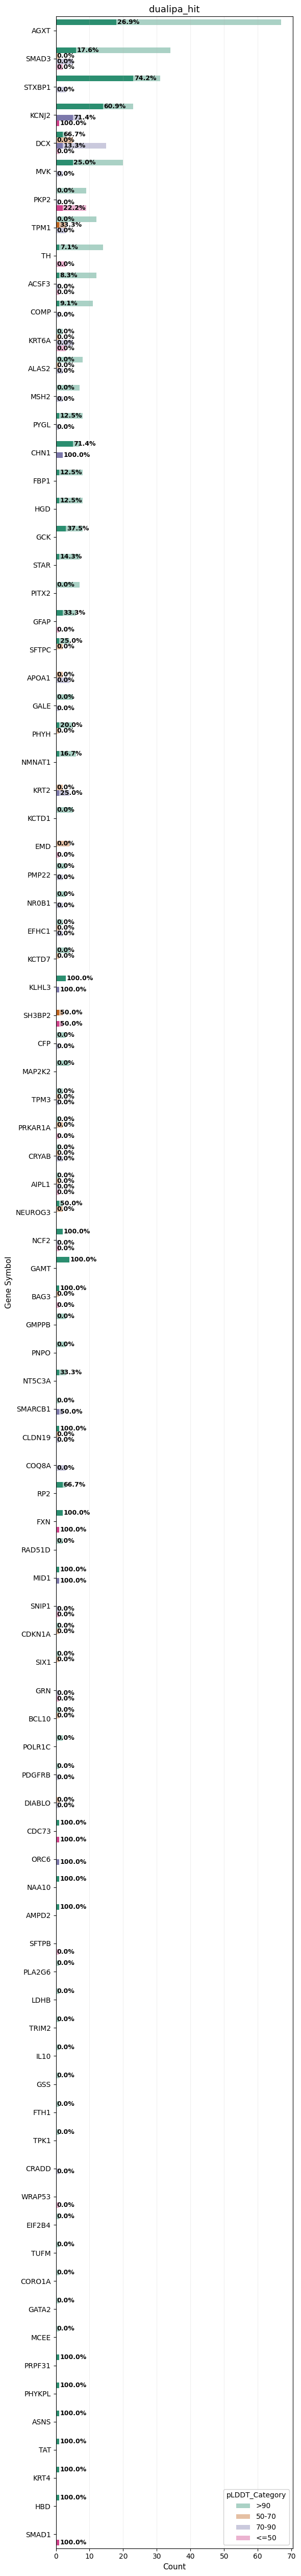

,symbol,pLDDT_Category,total_counts,hit_counts,hit_perc,total_counts_all
0,AGXT,>90,67,18,26.865672,67
1,SMAD3,50-70,1,0,0.000000,42
2,SMAD3,70-90,5,0,0.000000,42
3,SMAD3,<=50,2,0,0.000000,42
4,SMAD3,>90,34,6,17.647059,42
...,...,...,...,...,...,...
153,ASNS,>90,1,1,100.000000,1
154,TAT,>90,1,1,100.000000,1
155,KRT4,>90,1,1,100.000000,1
156,HBD,>90,1,1,100.000000,1


In [35]:
plot_gene_level_summary(
    assay_df=dual_ipa_df_clean_hit.filter(
        pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","4_VUS"])
    ),
    assay="dualipa_hit",
    cat="RSA_Category",
    palette="Dark2"
)

plot_gene_level_summary(
    assay_df=dual_ipa_df_clean_hit.filter(
        pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","4_VUS"])
    ),
    assay="dualipa_hit",
    cat="pLDDT_Category",
    palette="Dark2"
)